In [1]:
import polars as pl
import matplotlib.pyplot as plt
data = pl.read_parquet("../strategy_close_imbalance_plots/backtest_panel.parquet")
data

date,symbol,side,bid_px,ask_px,ref_price,total_imbalance_qty,imb_dollar_qty,session_dollar_volume,qty_signal,auction_px,passed_dollar_filter,passed_qty_filter,traded,sign,entry_px,exit_px,qty,gross_pnl,commission,pnl
date,str,str,f64,f64,f64,i64,f64,f64,f64,f64,bool,bool,bool,i8,f64,f64,i64,f64,f64,f64
2026-04-27,"""CEG""","""66""",314.85,314.88,314.9,111753,3.5191e7,1.1962e8,0.294181,315.17,true,true,true,1,314.88,315.17,5,1.45,0.035,1.415
2026-04-27,"""GILT""","""65""",17.43,17.48,17.43,3468,-60447.24,1.1916e6,-0.050726,17.37,false,true,false,null,null,null,null,null,null,null
2026-04-27,"""DKNG""","""65""",23.72,23.73,23.72,202252,-4.7974e6,5.4534e7,-0.087971,23.53,true,true,true,-1,23.72,23.53,70,13.3,0.49,12.81
2026-04-27,"""CMCT""","""65""",5.0,5.31,5.12,40,-204.8,49251.165,-0.004158,5.26,false,false,false,null,null,null,null,null,null,null
2026-04-27,"""CGEN""","""65""",2.9,2.91,2.9,303,-878.7,692739.845,-0.001268,2.92,false,false,false,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-05-22,"""AIRTP""","""65""",19.01,19.25,19.01,1,-19.01,95.25,-0.19958,19.05,false,true,false,null,null,null,null,null,null,null
2026-05-22,"""FBYDW""","""66""",1.97,2.87,2.5,1,2.5,0.0,NaN,2.5,false,false,false,null,null,null,null,null,null,null
2026-05-22,"""MAYS""","""66""",41.0,44.41,41.86,26,1088.36,2135.52,0.509646,41.0,false,true,false,null,null,null,null,null,null,null


In [17]:
net_pnl_sym = (data
               .filter(pl.col("traded") == True)
               .group_by(["symbol", "date"], maintain_order=True).agg(pl.col("pnl").sum())
)
net_pnl_sym['pnl'].describe()

statistic,value
str,f64
"""count""",11321.0
"""null_count""",0.0
"""mean""",0.810461
"""std""",8.862274
"""min""",-89.532
"""25%""",-3.078
"""50%""",0.234
"""75%""",4.368
"""max""",151.677


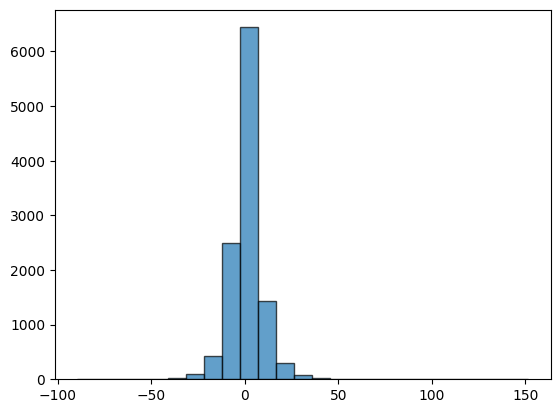

In [16]:
plt.hist(net_pnl_sym['pnl'], bins=25, edgecolor='black', alpha=0.7, log=False)
plt.show()

In [44]:
qtl_imb = data.with_columns(
    pl.col("imb_dollar_qty").qcut(10, labels=["Q" + str(i) for i in range(1,11)]).alias("qtl_imb")
).select(["date", "symbol", "traded", "qtl_imb", "pnl"])
qtl_imb

date,symbol,traded,qtl_imb,pnl
date,str,bool,cat,f64
2026-04-27,"""CEG""",true,"""Q10""",1.415
2026-04-27,"""GILT""",false,"""Q4""",null
2026-04-27,"""DKNG""",true,"""Q1""",12.81
2026-04-27,"""CMCT""",false,"""Q5""",null
2026-04-27,"""CGEN""",false,"""Q5""",null
…,…,…,…,…
2026-05-22,"""AIRTP""",false,"""Q6""",null
2026-05-22,"""FBYDW""",false,"""Q6""",null
2026-05-22,"""MAYS""",false,"""Q6""",null


In [45]:
(qtl_imb
 .filter(pl.col("traded") == True)
 .group_by(["qtl_imb"], maintain_order=True).agg(pl.col("pnl").sum())
)

qtl_imb,pnl
cat,f64
"""Q10""",5304.9439
"""Q1""",3249.533
"""Q2""",-777.359
"""Q9""",1398.111


In [27]:
trades = pl.read_parquet("../strategy_close_imbalance_plots/trades.parquet")
trades

date,symbol,side,qty,entry_px,exit_px,notional,gross_pnl,commission,pnl
date,str,i8,i64,f64,f64,f64,f64,f64,f64
2026-04-27,"""CEG""",1,5,314.88,315.17,1574.4,1.45,0.035,1.415
2026-04-27,"""DKNG""",-1,70,23.72,23.53,-1660.4,13.3,0.49,12.81
2026-04-27,"""AVGO""",1,3,417.48,418.2,1252.44,2.16,0.021,2.139
2026-04-27,"""SOXX""",-1,3,455.09,455.41,-1365.27,-0.96,0.021,-0.981
2026-04-27,"""NMRK""",-1,101,16.41,16.42,-1657.41,-1.01,0.707,-1.717
…,…,…,…,…,…,…,…,…,…
2026-05-22,"""DGRW""",1,19,96.29,96.33,1829.51,0.76,0.133,0.627
2026-05-22,"""CGON""",-1,29,64.42,64.25,-1868.18,4.93,0.203,4.727
2026-05-22,"""SHLS""",1,191,9.88,9.91,1887.08,5.73,1.337,4.393


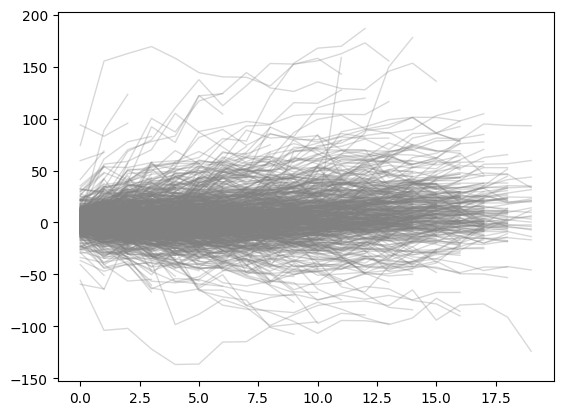

In [38]:
pnl_per_symbol = trades.group_by(["symbol"]).agg(pl.col("pnl").cum_sum())
for i in range(len(pnl_per_symbol)):
    plt.plot(pnl_per_symbol[i]['pnl'].item().to_numpy(), color='gray', linewidth=1, alpha=0.3)
plt.show()